In [117]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Readmission study

Exploratory analysis of synthetic hospital admissions data. Worked example to get used to integration of SQL, python (in particular venv) and using AI coding.


## Import libraries

In [118]:
from pathlib import Path
import sys

project_root = Path.cwd().parent
sys.path.append(str(project_root))

In [119]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
from datetime import date
from IPython.display import display
from src.db_config import DATABASE_URL
from src.readmission_analysis import (
    build_discharge_outcomes,
    summarize_readmissions,
)
from src.plot_functions import (
    plot_rates,
)

## Connect to database

In [120]:
engine = create_engine(DATABASE_URL)

In [121]:
STUDY_START_DATE = date(2019, 1, 1)
STUDY_END_DATE = date(2023, 12, 31)
READMISSION_WINDOW = 30

## Patient demographics

In [122]:
query = f"""
WITH reference_date AS (
    SELECT DATE '{STUDY_END_DATE}' AS reference_date
    FROM admissions
)
SELECT
    p.patient_id,
    p.sex,
    p.dob,
    r.reference_date,
    EXTRACT(YEAR FROM AGE(r.reference_date, p.dob))::INT
        AS age_at_reference_date
FROM patients AS p
CROSS JOIN reference_date AS r
ORDER BY p.patient_id
"""

In [123]:
df_demographics = pd.read_sql(query, engine)
df_demographics

,patient_id,sex,dob,reference_date,age_at_reference_date
0,1,Female,1981-05-13,2023-12-31,42
1,1,Female,1981-05-13,2023-12-31,42
2,1,Female,1981-05-13,2023-12-31,42
3,1,Female,1981-05-13,2023-12-31,42
4,1,Female,1981-05-13,2023-12-31,42
...,...,...,...,...,...
3440995,1000,Male,1986-04-05,2023-12-31,37
3440996,1000,Male,1986-04-05,2023-12-31,37
3440997,1000,Male,1986-04-05,2023-12-31,37
3440998,1000,Male,1986-04-05,2023-12-31,37


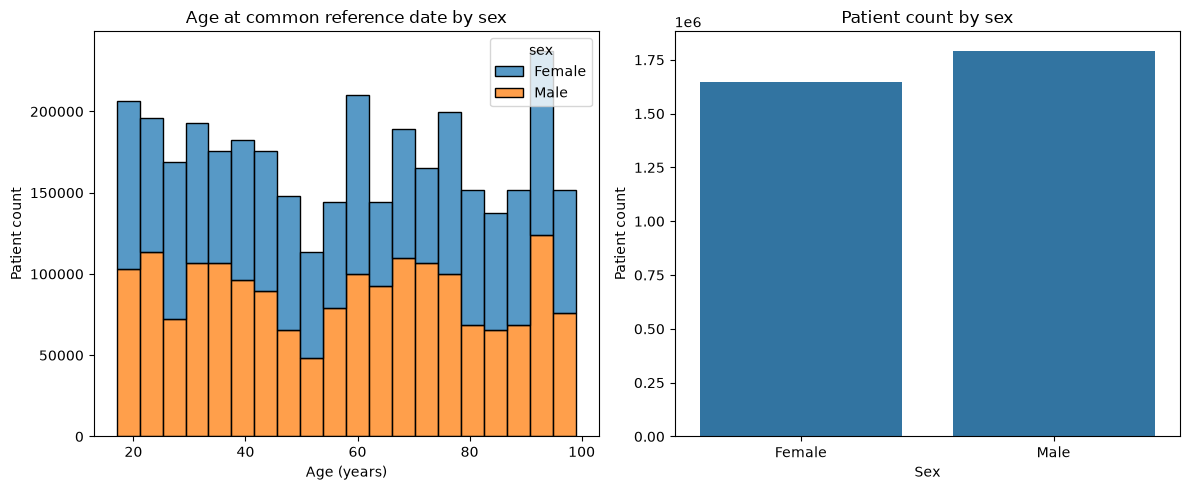

In [124]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(
    data=df_demographics,
    x="age_at_reference_date",
    hue="sex",
    bins=20,
    multiple="stack",
    ax=axes[0]
)
axes[0].set_title("Age at common reference date by sex")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Patient count")

sns.countplot(data=df_demographics, x="sex", ax=axes[1])
axes[1].set_title("Patient count by sex")
axes[1].set_xlabel("Sex")
axes[1].set_ylabel("Patient count")

fig.tight_layout()

## Average length of stay by diagnosis

In [125]:
query = """
SELECT
    diagnosis,
    AVG(discharge_date - admission_date) AS avg_los
FROM admissions
GROUP BY diagnosis
ORDER BY avg_los DESC
"""


In [126]:
df = pd.read_sql(query, engine) 
df

,diagnosis,avg_los
0,Chest pain,7.794521
1,Sepsis,7.595442
2,Chronic obstructive pulmonary disease,7.559889
3,Hip fracture,7.527108
4,Type 2 diabetes,7.492386
5,Kidney disease,7.485549
6,Heart failure,7.468843
7,Urinary tract infection,7.366477
8,Stroke,7.293051
9,Pneumonia,7.279539


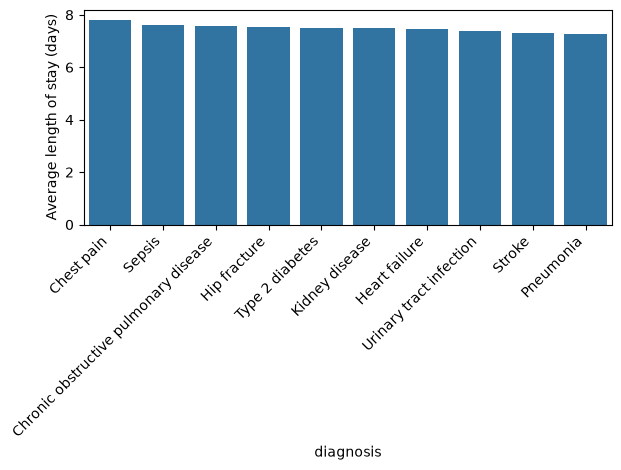

In [127]:


ax = sns.barplot(
    data=df,
    x="diagnosis",
    y="avg_los"
)
ax.set_ylabel("Average length of stay (days)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

## First diagnosis per patient and disease

In [128]:
first_diagnoses_query = """
WITH ranked_admissions AS (
    SELECT
        a.patient_id,
        a.diagnosis,
        a.admission_date AS first_diagnosis_date,
        p.dob,
        ROW_NUMBER() OVER (
            PARTITION BY a.patient_id, a.diagnosis
            ORDER BY a.admission_date, a.admission_id
        ) AS diagnosis_rank
    FROM admissions AS a
    JOIN patients AS p ON a.patient_id = p.patient_id
)
SELECT patient_id, diagnosis, first_diagnosis_date, dob
FROM ranked_admissions
WHERE diagnosis_rank = 1
ORDER BY patient_id, first_diagnosis_date, diagnosis
"""

In [129]:
df_first_diagnoses = pd.read_sql(first_diagnoses_query, engine)
df_first_diagnoses

,patient_id,diagnosis,first_diagnosis_date,dob
0,1,Type 2 diabetes,2019-05-18,1981-05-13
1,1,Heart failure,2019-12-30,1981-05-13
2,2,Chronic obstructive pulmonary disease,2021-04-04,1926-03-30
3,2,Type 2 diabetes,2021-05-14,1926-03-30
4,2,Heart failure,2021-09-30,1926-03-30
...,...,...,...,...
2363,1000,Pneumonia,2020-05-04,1986-04-05
2364,1000,Chronic obstructive pulmonary disease,2020-05-22,1986-04-05
2365,1000,Urinary tract infection,2021-03-24,1986-04-05
2366,1000,Sepsis,2021-04-24,1986-04-05


## Average age by first diagnosis

In [130]:
df_first_diagnoses["dob"] = pd.to_datetime(df_first_diagnoses["dob"])
df_first_diagnoses["first_diagnosis_date"] = pd.to_datetime(
    df_first_diagnoses["first_diagnosis_date"]
)

df_first_diagnoses["age_at_diagnosis"] = (
    (df_first_diagnoses["first_diagnosis_date"] - df_first_diagnoses["dob"])
    .dt.days / 365.25
) 

In [131]:
avg_age_by_first_diagnosis = (
    df_first_diagnoses.groupby("diagnosis", as_index=False)["age_at_diagnosis"]
    .mean()
    .rename(columns={"age_at_diagnosis": "avg_age"})
    .sort_values("avg_age", ascending=False)
)
avg_age_by_first_diagnosis

,diagnosis,avg_age
1,Chronic obstructive pulmonary disease,59.124606
8,Type 2 diabetes,56.826894
4,Kidney disease,56.060562
2,Heart failure,55.348637
7,Stroke,55.030729
3,Hip fracture,54.750651
0,Chest pain,54.681686
6,Sepsis,54.358998
5,Pneumonia,54.179050
9,Urinary tract infection,53.715556


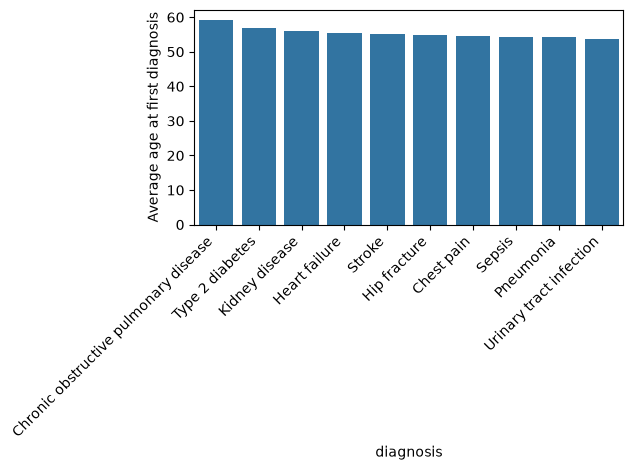

In [132]:
ax = sns.barplot(
    data=avg_age_by_first_diagnosis,
    x="diagnosis",
    y="avg_age"
)
ax.set_ylabel("Average age at first diagnosis")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

## Readmission
ground truth readmission reason

In [133]:
query = """
SELECT
    readmission_reason,
    COUNT(*) AS readmission_count
FROM admissions
GROUP BY readmission_reason
ORDER BY readmission_count DESC
"""
df = pd.read_sql(query, engine) 
df

,readmission_reason,readmission_count
0,new_episode,1661
1,index_admission,830
2,unplanned_related,403
3,unplanned_unrelated,277
4,planned_follow_up,270


## 30-day readmission outcomes

Each eligible discharge is one index event. The primary endpoint counts any
unplanned admission within 30 days, even if a planned return happened first.
The secondary all-cause endpoint counts any return. Discharges without a full
30 days of observation by the study end are censored and excluded from both
denominators.

Intervals are 95% patient-cluster bootstrap intervals because patients may
contribute multiple eligible discharges. Results describe the synthetic
scenario only.

In [ ]:
query = """
SELECT
    a.admission_id,
    a.patient_id,
    a.admission_date,
    a.discharge_date,
    a.diagnosis,
    a.readmission_reason,
    p.sex
FROM admissions AS a
JOIN patients AS p USING (patient_id)
ORDER BY a.patient_id, a.admission_date, a.admission_id
"""
all_admissions = pd.read_sql(query, engine)
readmission_outcomes = build_discharge_outcomes(
    all_admissions,
    study_end=STUDY_END_DATE,
    readmission_window_days=READMISSION_WINDOW,
)
readmission_summary = summarize_readmissions(readmission_outcomes)


,endpoint,events,eligible_discharges,patients,rate_percent,lower_95_ci_percent,upper_95_ci_percent
0,30-day unplanned,692,3347,815,20.7,19.3,22.1
1,30-day all-cause,940,3347,815,28.1,26.6,29.5


In [188]:
readmission_summary

,endpoint,events,eligible_discharges,patients,rate,ci_lower,ci_upper
0,30-day unplanned,692,3347,815,0.206752,0.192960,0.220741
1,30-day all-cause,940,3347,815,0.280849,0.266359,0.295293


In [195]:
sex_summaries = []

for (sex), subset in readmission_outcomes.groupby("sex"):

    summary = summarize_readmissions(
        subset,
        bootstrap_replicates=2000,
    )

    summary["sex"] = sex

    sex_summaries.append(summary)

sex_ci = pd.concat(sex_summaries,ignore_index=True)

sex_ci

,endpoint,events,eligible_discharges,patients,rate,ci_lower,ci_upper,sex
0,30-day unplanned,309,1567,382,0.197192,0.177361,0.217927,Female
1,30-day all-cause,429,1567,382,0.273772,0.252291,0.294533,Female
2,30-day unplanned,383,1780,433,0.215169,0.195779,0.234989,Male
3,30-day all-cause,511,1780,433,0.287079,0.267180,0.307737,Male


<Axes: xlabel='Readmission rate'>

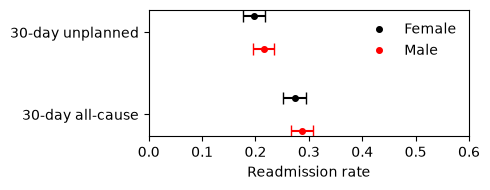

In [205]:
from src.plot_functions import (
    plot_rates,
)

fig, axes = plt.subplots(
    figsize=(5, 2),
    sharey=True
)

sex_ci["diagnosis_labels"]=sex_ci["endpoint"]

plot_rates(sex_ci)


In [138]:
diagnosis_summaries = []

for (sex,diagnosis), subset in readmission_outcomes.groupby(["sex", "index_diagnosis"]):

    summary = summarize_readmissions(
        subset,
        bootstrap_replicates=2000,
    )

    summary["sex"] = sex
    summary["diagnosis"] = diagnosis

    diagnosis_summaries.append(summary)

diagnosis_ci = pd.concat(diagnosis_summaries,ignore_index=True)

In [143]:
diagnosis_ci[diagnosis_ci["diagnosis"]=="Chest pain"]

,endpoint,events,eligible_discharges,patients,rate,ci_lower,ci_upper,sex,diagnosis
0,30-day unplanned,26,139,100,0.187050,0.115108,0.255667,Female,Chest pain
1,30-day all-cause,36,139,100,0.258993,0.175989,0.335766,Female,Chest pain
20,30-day unplanned,35,142,100,0.246479,0.170213,0.320903,Male,Chest pain
21,30-day all-cause,41,142,100,0.288732,0.201455,0.369438,Male,Chest pain


In [168]:
diagnosis_ci["diagnosis_labels"]=diagnosis_ci["diagnosis"]
diagnosis_labels_edits = {
    "Chronic obstructive pulmonary disease":
        "Chronic obstructive\npulmonary disease"
}
diagnosis_ci["diagnosis_labels"]=diagnosis_ci["diagnosis_labels"].replace(diagnosis_labels_edits)

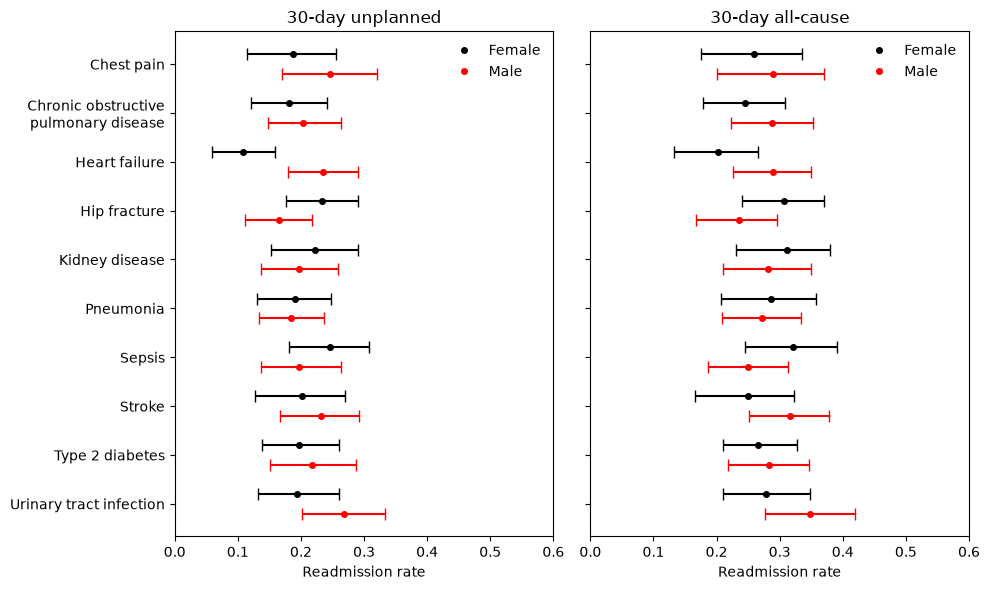

In [187]:
from src.plot_functions import (
    plot_rates,
)

fig, axes = plt.subplots(
    ncols=2,
    figsize=(10, 6),
    sharey=True
)

diagnosis_ci_unplanned = diagnosis_ci[diagnosis_ci["endpoint"] == "30-day unplanned"]
plot_rates(diagnosis_ci_unplanned, ax=axes[0])

diagnosis_ci_all_cause = diagnosis_ci[diagnosis_ci["endpoint"] == "30-day all-cause"]
plot_rates(diagnosis_ci_all_cause, ax=axes[1])

axes[0].set_title("30-day unplanned")
axes[1].set_title("30-day all-cause")

fig.tight_layout()

In [83]:
diagnosis_ci

,endpoint,events,eligible_discharges,patients,rate,ci_lower,ci_upper,sex,diagnosis
0,30-day unplanned,26,139,100,0.187050,0.115108,0.255667,Female,Chest pain
2,30-day unplanned,32,176,117,0.181818,0.120874,0.241393,Female,Chronic obstructive pulmonary disease
4,30-day unplanned,16,148,105,0.108108,0.058384,0.158952,Female,Heart failure
6,30-day unplanned,38,163,109,0.233129,0.176101,0.290327,Female,Hip fracture
8,30-day unplanned,37,167,110,0.221557,0.151889,0.290164,Female,Kidney disease
10,30-day unplanned,28,147,103,0.190476,0.130137,0.248227,Female,Pneumonia
12,30-day unplanned,42,171,113,0.245614,0.181250,0.308140,Female,Sepsis
14,30-day unplanned,25,124,87,0.201613,0.127982,0.270496,Female,Stroke
16,30-day unplanned,37,188,122,0.196809,0.138298,0.260417,Female,Type 2 diabetes
18,30-day unplanned,28,144,105,0.194444,0.132343,0.260571,Female,Urinary tract infection
